# Fase 2 — Análisis inferencial: videojuegos y rendimiento académico

**Integrantes:** José Zaavedra · Nicolás Arza  
**Pregunta de investigación:** ¿cómo se asocian las horas de videojuegos con el rendimiento académico, considerando estudio, sueño y asistencia?

Este notebook cubre la Fase 2: correcciones identificadas en la Fase 1, cuatro hipótesis, comprobación de supuestos, contrastes, intervalos de confianza, tamaños del efecto, corrección por comparaciones múltiples y conclusiones. No incluye el informe PDF ni el modelo predictivo de la Fase 3.

> **Alcance:** se analiza un dataset simulado y transversal. Los resultados describen asociaciones en el archivo recibido; no demuestran causalidad ni garantizan representatividad de una población real.

## Índice

1. Correcciones de la Fase 1
2. Hipótesis y plan de análisis
3. Configuración, carga y auditoría de datos
4. C1 — Correlaciones
5. C2 — Comparación de tres grupos
6. C3 — Regresión lineal múltiple
7. C4 — Factorial de dos factores
8. Bootstrap frente a un intervalo clásico
9. Corrección por comparaciones múltiples y tabla resumen
10. Conclusiones y limitaciones

**Reproducibilidad:** ejecutar todas las celdas en orden. Se fijan semillas aleatorias y se exporta la tabla de contrastes a CSV.

## 1. Correcciones metodológicas identificadas en la Fase 1

Esta lista se conserva para incluirla al inicio del informe de Fase 2.

| # | Hallazgo | Tratamiento en esta Fase 2 |
|---|---|---|
| 1 | La conclusión previa mencionaba coeficientes y métricas predictivas que no se podían reproducir desde las celdas ejecutadas. | Esta fase se limita a inferencia; la evaluación predictiva queda fuera del notebook y corresponde a la Fase 3. |
| 2 | Había listas diferentes de hipótesis (H1–H4 y H1–H5). | Se unifican en cuatro hipótesis y se vinculan con los contrastes de esta fase. |
| 3 | `gaming_cat × stress_level` presenta combinaciones sin observaciones, por lo que no es una buena elección para el factorial principal. | Se analiza la interacción `gaming_cat × study_cat`, cuyas nueve combinaciones sí están observadas. |
| 4 | Se habían mencionado distintos puntos de corte para horas de gaming. | Se utilizan los terciles `Bajo`, `Medio` y `Alto`; no se interpretan como umbrales naturales. |
| 5 | El archivo limpio no contiene `student_id`. | Se documenta que no puede comprobarse la unicidad individual ni certificarse independencia mediante un identificador. |
| 6 | El análisis previo no conservaba los resultados ejecutados en el notebook. | Se guardan las salidas de los contrastes y se exporta la tabla resumen. |

La auditoría también documenta el tope de `grades` en 100 y el valor de `grades_original` que supera ese tope. El análisis principal utiliza `grades`, tal como aparece en el dataset limpio.

## 2. Hipótesis y plan de análisis

Se fija **α = 0,05 antes de ejecutar los contrastes**. Las alternativas son bilaterales. Las direcciones positivas o negativas son expectativas previas, no restricciones impuestas al cálculo.

### H1 — Horas de videojuegos y rendimiento académico

- **H₀ formal (correlación):** ρₛ(`gaming_hours`, `grades`) = 0. **H₁ formal:** ρₛ(`gaming_hours`, `grades`) ≠ 0.
- **H₀ formal (regresión ajustada):** β(`gaming_hours`) = 0, manteniendo constantes los demás predictores del modelo. **H₁ formal:** β(`gaming_hours`) ≠ 0.
- **H₀ en lenguaje natural:** en estos datos, las horas de videojuegos no presentan una asociación monotónica con las calificaciones; además, al considerar los demás predictores, no se observa una asociación lineal independiente de gaming con la calificación.
- **H₁ en lenguaje natural:** las horas de videojuegos presentan una asociación con las calificaciones; se espera que sea negativa. Esta hipótesis describe una asociación, no un efecto causal.
- **Contrastes:** C1-1, C3-gaming_hours y, como comparación complementaria, C2.

### H2 — Horas de estudio y rendimiento académico

- **H₀ formal (correlación):** ρₛ(`study_hours`, `grades`) = 0. **H₁ formal:** ρₛ(`study_hours`, `grades`) ≠ 0.
- **H₀ formal (regresión ajustada):** β(`study_hours`) = 0, manteniendo constantes los demás predictores. **H₁ formal:** β(`study_hours`) ≠ 0.
- **H₀ en lenguaje natural:** las horas de estudio no presentan una asociación monotónica con las calificaciones ni una asociación lineal independiente al considerar los demás predictores.
- **H₁ en lenguaje natural:** las horas de estudio se asocian con las calificaciones; se espera que la asociación sea positiva.
- **Contrastes:** C1-2, C3-study_hours y el efecto principal complementario C4-S.

### H3 — Interacción entre gaming y estudio

- **H₀ formal:** todos los coeficientes de interacción entre `gaming_cat` y `study_cat` son cero en el modelo factorial.
- **H₁ formal:** al menos un coeficiente de interacción entre `gaming_cat` y `study_cat` es distinto de cero.
- **H₀ en lenguaje natural:** las diferencias de calificación entre los niveles de gaming son similares para todos los niveles de estudio; no se observa interacción.
- **H₁ en lenguaje natural:** la relación entre el nivel de gaming y las calificaciones cambia según el nivel de estudio.
- **Contraste principal:** C4-INT.

### H4a — Sueño y rendimiento académico

- **H₀ formal:** ρₛ(`sleep_hours`, `grades`) = 0. **H₁ formal:** ρₛ(`sleep_hours`, `grades`) ≠ 0.
- **H₀ en lenguaje natural:** las horas de sueño no presentan una asociación monotónica con la calificación ni una asociación lineal independiente al considerar los demás predictores.
- **H₁ en lenguaje natural:** las horas de sueño se asocian con la calificación; se espera que la asociación sea positiva.
- **Contrastes:** C1-3 y C3-sleep_hours.

### H4b — Asistencia y rendimiento académico

- **H₀ formal:** ρₛ(`attendance`, `grades`) = 0. **H₁ formal:** ρₛ(`attendance`, `grades`) ≠ 0.
- **H₀ en lenguaje natural:** la asistencia no presenta una asociación monotónica con la calificación ni una asociación lineal independiente al considerar los demás predictores.
- **H₁ en lenguaje natural:** la asistencia se asocia con la calificación; se espera que la asociación sea positiva.
- **Contrastes:** C1-4 y C3-attendance.

Ambas hipótesis se contrastan por separado. La corrección Benjamini–Hochberg se mantiene por familia estadística: correlaciones, coeficientes de regresión y demás contrastes.

### Plan de análisis

| ID | Pregunta | Método previsto según los supuestos |
|---|---|---|
| C1 | Asociación entre cada variable cuantitativa y `grades` | Spearman cuando los diagnósticos lo aconsejan; Pearson con IC de Fisher solo si los diagnósticos son razonables. |
| C2 | Diferencias de rendimiento entre tres terciles de gaming | ANOVA de un factor con Tukey o Kruskal–Wallis con Dunn, de acuerdo con los supuestos. |
| C3 | Asociación ajustada de varios predictores con `grades` | Regresión lineal múltiple con F global y t por coeficiente. Ante la alerta de normalidad de residuos, inferencia por permutación y IC de coeficientes por bootstrap. |
| C4 | Efectos de gaming, estudio y su interacción | ANOVA de dos factores o modelo por permutación si los supuestos paramétricos no son razonables. |
| B1 | Incertidumbre de un parámetro | IC bootstrap comparado con el IC clásico correspondiente; es una estimación, no una prueba adicional. |

Si se realizan varias pruebas dentro de una misma familia, se usa Benjamini–Hochberg. Los valores p se interpretan junto con los intervalos de confianza y los tamaños del efecto. En ningún caso se interpreta una asociación observacional como causalidad.

## 3. Configuración, carga y auditoría de los datos

Las rutas están preparadas para un repositorio ordenado (`data/processed/`) o para ejecutar el notebook junto al CSV descargado. No se crea ni se simula una columna identificadora que no esté en el archivo.

In [1]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from patsy import dmatrix
from IPython.display import display

SEED = 20261010
ALPHA = 0.05                 # Declarado antes de cualquier contraste
N_BOOT_CORE = 10_000         # Bootstrap principal (correlación y diferencia de medias)
N_BOOT_EFFECT = 2_000        # IC bootstrap para efectos no paramétricos
N_BOOT_FACTORIAL = 1_000     # IC bootstrap para efectos del factorial
N_PERM_FACTORIAL = 999       # p por permutación factorial: resolución mínima 0,001
N_PERM_REGRESSION = 1999      # p por permutación en C3: resolución mínima 0,0005
N_BOOT_REGRESSION = 1000      # IC percentil para coeficientes de C3
rng = np.random.default_rng(SEED)

print(f"Python/NumPy/pandas/SciPy/statsmodels: disponibles")
print(f"α predefinido = {ALPHA}; semilla = {SEED}")
print(f"Bootstrap principal = {N_BOOT_CORE:,}; permutaciones factoriales = {N_PERM_FACTORIAL:,}; "
      f"permutaciones de regresión = {N_PERM_REGRESSION:,}; bootstrap de coeficientes = {N_BOOT_REGRESSION:,}")

cwd = Path.cwd().resolve()
project_root = next(
    (
        candidate
        for candidate in (cwd, *cwd.parents)
        if (candidate / "data" / "processed" / "gaming_academic_clean.csv").is_file()
        and (candidate / "notebooks").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. Ejecutá el notebook desde la raíz "
        "o desde notebooks/, con data/processed/gaming_academic_clean.csv disponible."
    )
DATA_PATH = project_root / "data" / "processed" / "gaming_academic_clean.csv"

df = pd.read_csv(DATA_PATH)
OUTPUT_DIR = project_root / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Archivo cargado: {DATA_PATH.relative_to(project_root)}")
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())

Python/NumPy/pandas/SciPy/statsmodels: disponibles
α predefinido = 0.05; semilla = 20261010
Bootstrap principal = 10,000; permutaciones factoriales = 999; permutaciones de regresión = 1,999; bootstrap de coeficientes = 1,000
Archivo cargado: data\processed\gaming_academic_clean.csv
Dimensiones: 8,000 filas × 15 columnas


,age,gender,gaming_hours,study_hours,sleep_hours,attendance,social_activity,device_usage,uso_no_gaming,stress_level,gaming_cat,grades,grades_original,flag_grades_gt100,flag_ajustado
0,22,Male,7.23,8.78,6.96,91.44,3.25,9.36,2.13,Low,Alto,86.46,86.459555,False,True
1,19,Male,0.07,8.72,7.63,63.63,1.02,3.21,3.14,Medium,Bajo,98.23,98.230000,False,False
2,23,Female,1.73,9.56,4.40,83.26,3.46,5.56,3.83,High,Bajo,90.56,90.560000,False,False
3,20,Female,6.62,1.68,7.83,75.04,1.46,11.78,5.16,Low,Alto,32.67,32.670000,False,False
4,22,Female,5.36,5.83,5.55,65.57,1.01,8.23,2.87,Low,Medio,58.71,58.710000,False,False


In [2]:
# Comprobaciones reproducibles del archivo entregado.
required = {
    "gaming_hours", "study_hours", "sleep_hours", "attendance",
    "uso_no_gaming", "stress_level", "gaming_cat", "grades",
    "grades_original"
}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing_columns)}")

audit = pd.DataFrame({
    "indicador": [
        "filas", "columnas", "valores faltantes totales", "filas duplicadas completas",
        "student_id disponible", "notas grades = 100", "grades > 100 en limpio",
        "grades_original > 100"
    ],
    "valor": [
        len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum()),
        "sí" if "student_id" in df.columns else "no",
        int((df["grades"] == 100).sum()), int((df["grades"] > 100).sum()),
        int((df["grades_original"] > 100).sum())
    ]
})
display(audit)

if df[list(required)].isna().any().any():
    warnings.warn("Hay valores faltantes en columnas de análisis; se usarán casos completos por contraste.")

# Orden categórico fijado para tablas y modelos. Se valida que existan los tres terciles.
gaming_levels = ["Bajo", "Medio", "Alto"]
df["gaming_cat"] = pd.Categorical(df["gaming_cat"].astype(str).str.strip(), categories=gaming_levels, ordered=True)
df["study_cat"] = pd.qcut(df["study_hours"], q=3, labels=gaming_levels, duplicates="drop")
df["study_cat"] = pd.Categorical(df["study_cat"], categories=gaming_levels, ordered=True)

print("\nConteo de gaming_cat:")
display(df["gaming_cat"].value_counts().reindex(gaming_levels).rename("n").to_frame())
print("\nConteo de study_cat:")
display(df["study_cat"].value_counts().reindex(gaming_levels).rename("n").to_frame())
print("\nFaltantes por variable utilizada:")
display(df[list(required)].isna().sum().rename("faltantes").to_frame())

print("\nTabla gaming_cat × stress_level (diagnóstico de celdas vacías):")
stress_table = pd.crosstab(df["gaming_cat"], df["stress_level"])
display(stress_table)
if (stress_table == 0).any().any():
    print("AVISO: hay combinaciones con frecuencia observada cero; estrés no se usará en el factorial principal.")

,indicador,valor
0,filas,8000
1,columnas,15
2,valores faltantes totales,0
3,filas duplicadas completas,0
4,student_id disponible,no
5,notas grades = 100,574
6,grades > 100 en limpio,0
7,grades_original > 100,134



Conteo de gaming_cat:


,n
gaming_cat,
Bajo,2671
Medio,2667
Alto,2662



Conteo de study_cat:


,n
study_cat,
Bajo,2668
Medio,2669
Alto,2663



Faltantes por variable utilizada:


,faltantes
stress_level,0
study_hours,0
grades,0
gaming_hours,0
uso_no_gaming,0
attendance,0
grades_original,0
sleep_hours,0
gaming_cat,0



Tabla gaming_cat × stress_level (diagnóstico de celdas vacías):


stress_level,High,Low,Medium
gaming_cat,,,
Bajo,336,0,2335
Medio,348,407,1912
Alto,326,2336,0


AVISO: hay combinaciones con frecuencia observada cero; estrés no se usará en el factorial principal.


### Funciones auxiliares y comprobación de supuestos

Antes de elegir cada contraste se revisa la normalidad con Shapiro–Wilk y gráficos Q–Q; Levene se aplica a comparaciones de grupos cuando corresponde. La independencia se documenta como una limitación: el archivo no incluye `student_id`, ni información sobre el muestreo o la dependencia temporal. En correlación y regresión, Levene no aplica como prueba de igualdad de varianzas entre grupos.

In [3]:
primary_records = []
posthoc_records = []


def shapiro_diag(values, label, seed=SEED):
    x = pd.Series(values).dropna().astype(float).to_numpy()
    if len(x) < 3:
        return {"variable": label, "n": len(x), "W": np.nan, "p_Shapiro": np.nan,
                "asimetría": np.nan, "nota": "n<3"}
    if len(x) > 5000:
        label_seed = int.from_bytes(label.encode("utf-8"), "little") % 100_000
        local_rng = np.random.default_rng(seed + label_seed)
        x_test = local_rng.choice(x, size=5000, replace=False)
        note = "submuestra aleatoria fija de 5000"
    else:
        x_test = x
        note = "muestra completa"
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        w, p = stats.shapiro(x_test)
    return {"variable": label, "n": len(x), "W": float(w), "p_Shapiro": float(p),
            "asimetría": float(stats.skew(x, bias=False)), "nota": note}


def plot_qq_grid(series_dict, title, ncols=3):
    items = list(series_dict.items())
    nrows = math.ceil(len(items) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.8*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (label, values) in zip(axes, items):
        x = pd.Series(values).dropna().astype(float).to_numpy()
        if len(x) > 5000:
            x = np.random.default_rng(SEED + len(label)).choice(x, 5000, replace=False)
        stats.probplot(x, dist="norm", plot=ax)
        ax.set_title(label)
        ax.grid(alpha=.2)
    for ax in axes[len(items):]:
        ax.axis("off")
    fig.suptitle(title, y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()


def fisher_ci(r, n, alpha=ALPHA):
    if n <= 3 or not np.isfinite(r) or abs(r) >= 1:
        return (np.nan, np.nan)
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    zcrit = stats.norm.ppf(1 - alpha/2)
    return tuple(np.tanh([z - zcrit*se, z + zcrit*se]))


def spearman_boot_ci(x, y, n_boot=2000, batch=50, seed=SEED):
    """IC percentil bootstrap para rho de Spearman; recalcula los rangos en cada remuestra."""
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    n = len(x); local_rng = np.random.default_rng(seed); values = []
    for start in range(0, n_boot, batch):
        b = min(batch, n_boot-start)
        ids = local_rng.integers(0, n, size=(b, n))
        xb, yb = x[ids], y[ids]
        rx, ry = rankdata(xb, axis=1), rankdata(yb, axis=1)
        rx = rx - rx.mean(axis=1, keepdims=True)
        ry = ry - ry.mean(axis=1, keepdims=True)
        numerator = np.sum(rx*ry, axis=1)
        denominator = np.sqrt(np.sum(rx*rx, axis=1)*np.sum(ry*ry, axis=1))
        values.extend((numerator/denominator).tolist())
    return tuple(np.nanpercentile(values, [100*ALPHA/2, 100*(1-ALPHA/2)]))


def bootstrap_pearson_ci(x, y, n_boot=N_BOOT_CORE, batch=100, seed=SEED):
    """IC percentil bootstrap de Pearson por lotes para limitar memoria."""
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    n = len(x); local_rng = np.random.default_rng(seed); values=[]
    for start in range(0, n_boot, batch):
        b = min(batch, n_boot-start)
        ids = local_rng.integers(0, n, size=(b, n))
        xb, yb = x[ids], y[ids]
        xc = xb - xb.mean(axis=1, keepdims=True)
        yc = yb - yb.mean(axis=1, keepdims=True)
        den = np.sqrt(np.sum(xc*xc, axis=1)*np.sum(yc*yc, axis=1))
        values.extend((np.sum(xc*yc, axis=1)/den).tolist())
    return tuple(np.nanpercentile(values, [100*ALPHA/2, 100*(1-ALPHA/2)]))


def bootstrap_median_diff_ci(x, y, n_boot=N_BOOT_EFFECT, batch=100, seed=SEED):
    """IC bootstrap para la diferencia de medianas, con remuestreo independiente por grupo."""
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    local_rng = np.random.default_rng(seed); values=[]
    for start in range(0, n_boot, batch):
        b = min(batch, n_boot-start)
        ix = local_rng.integers(0, len(x), size=(b, len(x)))
        iy = local_rng.integers(0, len(y), size=(b, len(y)))
        values.extend((np.median(x[ix], axis=1) - np.median(y[iy], axis=1)).tolist())
    return tuple(np.nanpercentile(values, [100*ALPHA/2, 100*(1-ALPHA/2)]))


def epsilon_squared_kw(h, n, k):
    return max(0.0, float((h - k + 1) / (n - k)))


def bootstrap_kw_effect_ci(groups, n_boot=N_BOOT_EFFECT, seed=SEED):
    local_rng = np.random.default_rng(seed)
    groups = [np.asarray(g, dtype=float) for g in groups]
    k = len(groups); n = sum(len(g) for g in groups); vals=[]
    for _ in range(n_boot):
        sample = [local_rng.choice(g, size=len(g), replace=True) for g in groups]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            h = stats.kruskal(*sample).statistic
        vals.append(epsilon_squared_kw(h, n, k))
    return tuple(np.nanpercentile(vals, [100*ALPHA/2, 100*(1-ALPHA/2)]))


def bootstrap_eta_squared_ci(groups, n_boot=N_BOOT_EFFECT, seed=SEED):
    local_rng = np.random.default_rng(seed)
    groups = [np.asarray(g, dtype=float) for g in groups]
    vals=[]
    for _ in range(n_boot):
        sample = [local_rng.choice(g, size=len(g), replace=True) for g in groups]
        all_values = np.concatenate(sample)
        grand = all_values.mean()
        ss_between = sum(len(g)*(g.mean()-grand)**2 for g in sample)
        ss_total = np.sum((all_values-grand)**2)
        vals.append(ss_between/ss_total if ss_total > 0 else np.nan)
    return tuple(np.nanpercentile(vals, [100*ALPHA/2, 100*(1-ALPHA/2)]))


def add_primary(test_id, hypothesis, contrast, family, test_name, statistic, df_text, p_value,
                ci_text, effect_text, assumptions, expected_direction, natural_interpretation=""):
    primary_records.append({
        "ID": test_id, "Hipótesis": hypothesis, "Contraste": contrast, "Familia": family,
        "Prueba aplicada": test_name, "Supuestos verificados": assumptions,
        "Estadístico (gl)": f"{statistic} ({df_text})", "p": float(p_value),
        "IC 95 %": ci_text, "Tamaño del efecto": effect_text,
        "Dirección esperada": expected_direction, "Interpretación base": natural_interpretation
    })


def fmt_ci(ci, digits=3):
    return f"[{ci[0]:.{digits}f}; {ci[1]:.{digits}f}]"


def format_p_report(p):
    if not np.isfinite(p): return "n.a."
    if p < 0.001: return "< 0,001"
    return f"{p:.3f}"


def effect_strength_corr(v):
    a=abs(float(v))
    if a < .10: return "muy pequeño/despreciable"
    if a < .30: return "pequeño"
    if a < .50: return "mediano"
    return "grande"


def cohens_d_independent(x, y):
    x=np.asarray(x); y=np.asarray(y)
    pooled=np.sqrt(((len(x)-1)*x.var(ddof=1)+(len(y)-1)*y.var(ddof=1))/(len(x)+len(y)-2))
    return (x.mean()-y.mean())/pooled if pooled else np.nan


def cliffs_delta_from_u(u_x, n_x, n_y):
    return 2*u_x/(n_x*n_y)-1


## 4. C1 — Correlaciones con `grades`

Se comprueban Shapiro–Wilk y los gráficos Q–Q antes de elegir el coeficiente. Si alguna de las dos variables muestra una desviación de normalidad, se utiliza Spearman; en caso contrario, Pearson con el IC clásico de Fisher. Para la variable no elegida como método principal solo se informa el coeficiente descriptivo, no un contraste adicional.

- `gaming_hours`: H₀: ρ = 0; H₁: ρ ≠ 0. Dirección esperada negativa.
- `study_hours`, `sleep_hours` y `attendance`: H₀: ρ = 0; H₁: ρ ≠ 0. Direcciones esperadas positivas.
- Se informan coeficiente, valor p, IC 95 % y tamaño del efecto. La independencia no se puede verificar con el archivo recibido.

Shapiro–Wilk y asimetría para las variables que entran en C1:


,variable,n,W,p_Shapiro,asimetría,nota
0,gaming_hours,8000,0.955171,1.145254e-36,-0.066434,submuestra aleatoria fija de 5000
1,study_hours,8000,0.956268,2.604695e-36,0.009731,submuestra aleatoria fija de 5000
2,sleep_hours,8000,0.957103,4.921446e-36,-0.000415,submuestra aleatoria fija de 5000
3,attendance,8000,0.953208,2.736682e-37,0.021198,submuestra aleatoria fija de 5000
4,grades,8000,0.971787,2.673887e-30,-0.283481,submuestra aleatoria fija de 5000


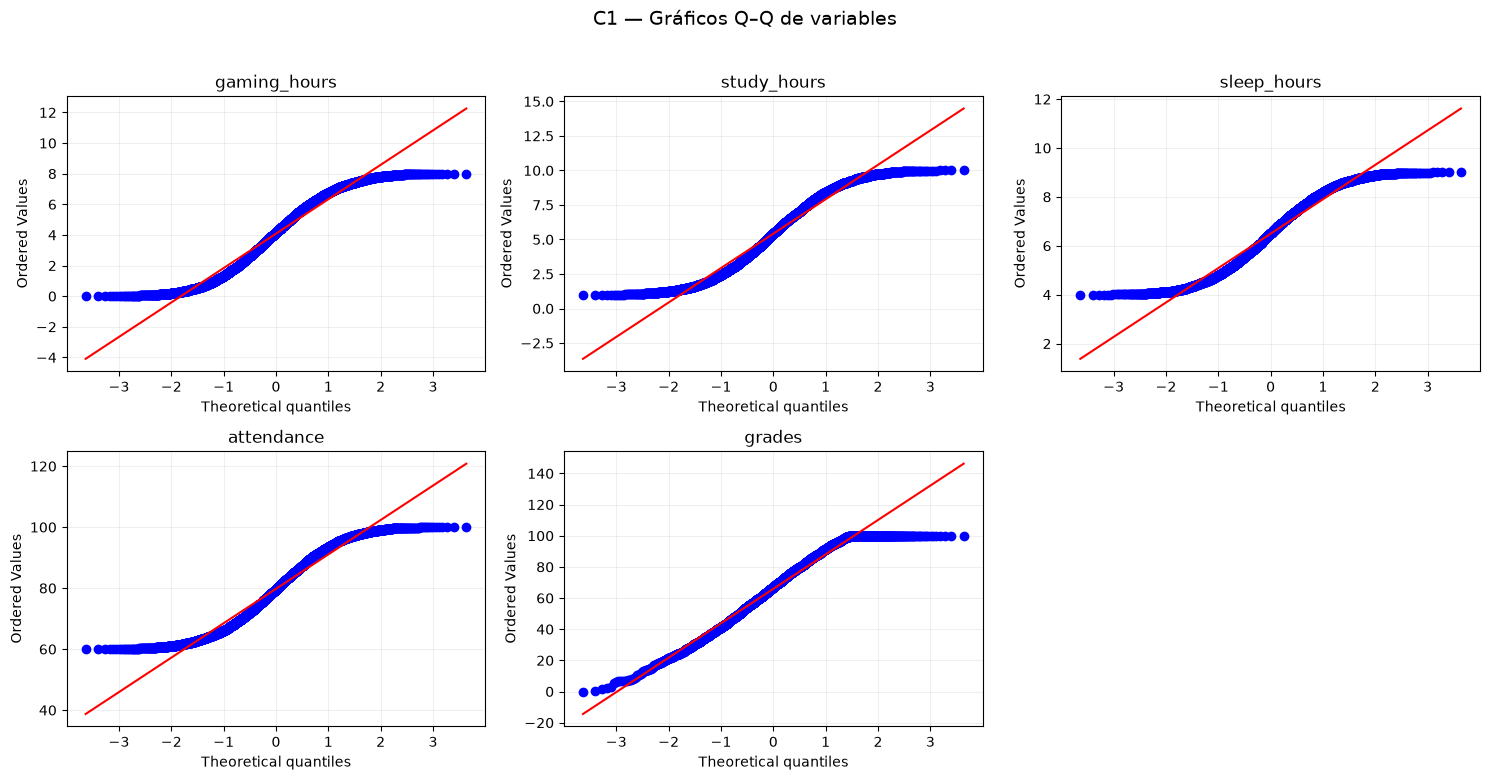

Resultados de correlación: se registra una sola prueba inferencial primaria por variable; no se cuentan p alternativos.


,variable,n,Pearson r,IC Fisher Pearson,Spearman rho,IC 95 % principal,prueba primaria,p principal,magnitud primaria,regla aplicada
0,gaming_hours,8000,-0.558230,[-0.573; -0.543],-0.547300,[-0.563; -0.531],Spearman,"< 0,001",grande,Spearman primario: Shapiro rechazó normalidad ...
1,study_hours,8000,0.733801,[0.724; 0.744],0.742025,[0.732; 0.751],Spearman,"< 0,001",grande,Spearman primario: Shapiro rechazó normalidad ...
2,sleep_hours,8000,0.245316,[0.225; 0.266],0.238530,[0.218; 0.260],Spearman,"< 0,001",pequeño,Spearman primario: Shapiro rechazó normalidad ...
3,attendance,8000,0.130105,[0.109; 0.152],0.125748,[0.104; 0.148],Spearman,"< 0,001",pequeño,Spearman primario: Shapiro rechazó normalidad ...


In [4]:
corr_vars = ["gaming_hours", "study_hours", "sleep_hours", "attendance"]
normality_corr = [shapiro_diag(df[v], v) for v in corr_vars + ["grades"]]
normality_corr_df = pd.DataFrame(normality_corr)
print("Shapiro–Wilk y asimetría para las variables que entran en C1:")
display(normality_corr_df)
plot_qq_grid({v: df[v] for v in corr_vars + ["grades"]}, "C1 — Gráficos Q–Q de variables")

corr_results=[]
normal_p = normality_corr_df.set_index("variable")["p_Shapiro"].to_dict()
for i, variable in enumerate(corr_vars):
    x=df[variable].astype(float).to_numpy(); y=df["grades"].astype(float).to_numpy()
    pearson_r = float(np.corrcoef(x, y)[0, 1])
    spearman_r, spearman_p = stats.spearmanr(x, y)
    use_spearman = (normal_p.get(variable, 1) < ALPHA) or (normal_p.get("grades", 1) < ALPHA)
    if use_spearman:
        main_name, main_stat, main_p, main_effect = "Spearman", spearman_r, spearman_p, spearman_r
        ci_main = spearman_boot_ci(x, y, n_boot=2000, batch=50, seed=SEED+i+1)
        decision_rule = "Spearman primario: Shapiro rechazó normalidad en x o grades; Q–Q visible arriba"
    else:
        pearson_test = stats.pearsonr(x, y)
        main_name, main_stat, main_p, main_effect = "Pearson", pearson_r, pearson_test.pvalue, pearson_r
        ci_main = fisher_ci(pearson_r, len(x))
        decision_rule = "Pearson primario; Q–Q y Shapiro sin evidencia clara de desviación"
    ci_pearson = fisher_ci(pearson_r, len(x))
    row={
        "variable": variable, "n": len(x), "Pearson r": pearson_r,
        "IC Fisher Pearson": fmt_ci(ci_pearson), "Spearman rho": spearman_r,
        "IC 95 % principal": fmt_ci(ci_main), "prueba primaria": main_name, "p principal": main_p,
        "magnitud primaria": effect_strength_corr(main_effect), "regla aplicada": decision_rule
    }
    corr_results.append(row)
    expected = "negativa" if variable=="gaming_hours" else "positiva"
    display_text = (f"La asociación observada entre {variable} y grades es {('negativa' if main_stat < 0 else 'positiva' if main_stat > 0 else 'nula')} "
                    f"(coeficiente {main_stat:.3f}; magnitud orientativa {effect_strength_corr(main_stat)}). "
                    "No demuestra causalidad.")
    assumptions = f"Shapiro x p={normal_p.get(variable, np.nan):.3g}; grades p={normal_p.get('grades', np.nan):.3g}; Q–Q generado; independencia no verificable por diseño; Levene no aplicable"
    add_primary(f"C1-{i+1}", "H1" if variable=="gaming_hours" else ("H2" if variable=="study_hours" else ("H4a" if variable=="sleep_hours" else "H4b")),
                f"{variable} ↔ grades", "Correlación", main_name,
                f"rho={main_stat:.4f}" if main_name=="Spearman" else f"r={main_stat:.4f}",
                "n.a.", main_p, fmt_ci(ci_main),
                f"{main_name}={main_stat:.3f} ({effect_strength_corr(main_stat)}); Pearson r descriptivo={pearson_r:.3f}",
                assumptions, f"asociación {expected}", display_text)

corr_results_df = pd.DataFrame(corr_results)
corr_results_df["p principal"]=corr_results_df["p principal"].map(format_p_report)
print("Resultados de correlación: se registra una sola prueba inferencial primaria por variable; no se cuentan p alternativos.")
display(corr_results_df)

## 5. C2 — Comparación de rendimiento entre tres grupos

**H₀:** las distribuciones de `grades` son iguales en los tres terciles de gaming. **H₁:** al menos una distribución difiere. **α = 0,05.**

Antes de elegir el método se revisan Shapiro–Wilk por grupo, Q–Q y Levene. Si algún diagnóstico indica que no se cumplen los supuestos, se utiliza Kruskal–Wallis con comparaciones post hoc de Dunn y ajuste BH; si los supuestos son razonables, se utiliza ANOVA de un factor con Tukey. Se informa el tamaño del efecto y su IC.

Normalidad por grupo:


,variable,n,W,p_Shapiro,asimetría,nota
0,grades | gaming_cat=Bajo,2671,0.934617,9.836115e-33,-0.415063,muestra completa
1,grades | gaming_cat=Medio,2667,0.981687,4.635378e-18,-0.041637,muestra completa
2,grades | gaming_cat=Alto,2662,0.982853,2.074401e-17,0.193406,muestra completa


Levene centrado en mediana: W=103.7731, p=3.212e-45


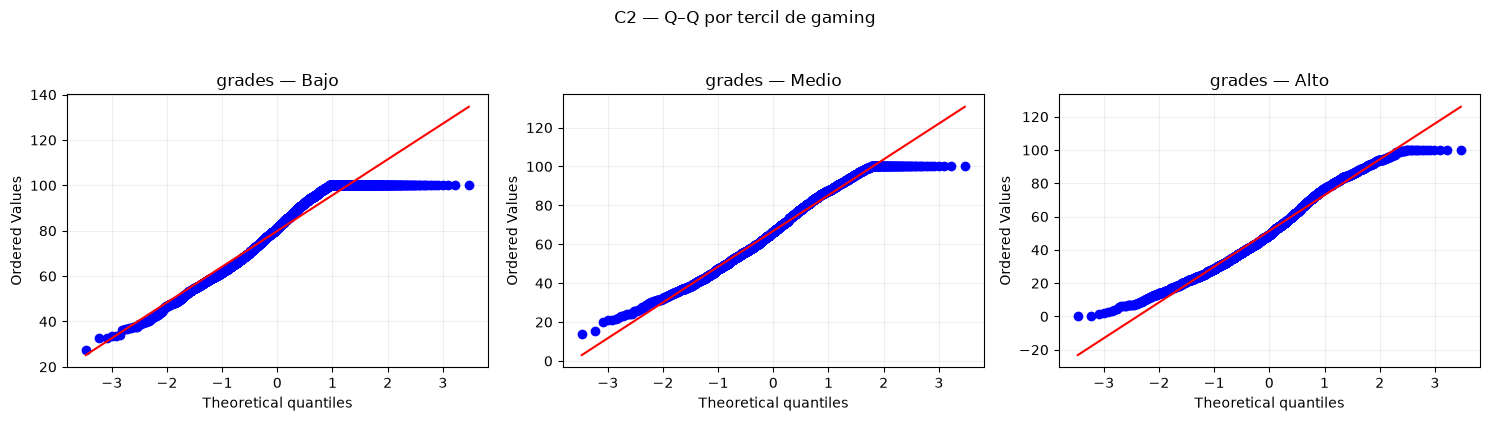

Vía principal no paramétrica: H(2)=2110.1479, p < 0,001; epsilon²=0.2636; IC bootstrap 95 % [0.247; 0.281]


Medias, medianas y dispersión por tercil:


,n,media,sd,mediana,q1,q3
gaming_cat,,,,,,
Bajo,2671,79.921778,16.292471,81.05,67.0450,95.3500
Medio,2667,66.870611,18.544932,66.39,53.3150,81.5000
Alto,2662,51.400635,21.659094,49.06,34.8125,68.1275


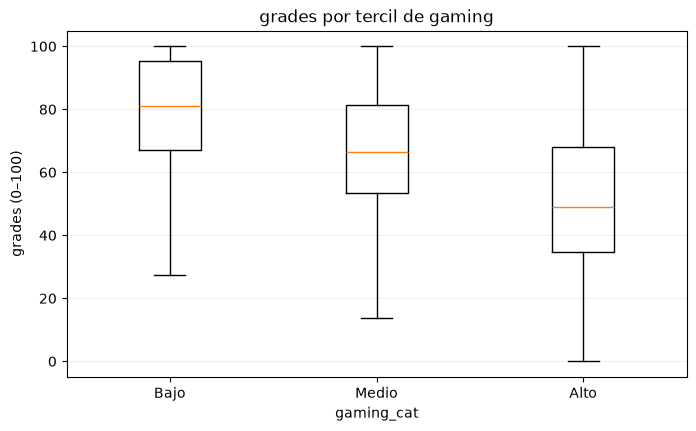

In [5]:
group_values = [df.loc[df["gaming_cat"]==g, "grades"].dropna().to_numpy() for g in gaming_levels]
normality_c2 = pd.DataFrame([shapiro_diag(v, f"grades | gaming_cat={g}", seed=SEED+i+20) for i,(g,v) in enumerate(zip(gaming_levels,group_values))])
levene_c2 = stats.levene(*group_values, center="median")
print("Normalidad por grupo:")
display(normality_c2)
print(f"Levene centrado en mediana: W={levene_c2.statistic:.4f}, p={levene_c2.pvalue:.4g}")

fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,g,vals in zip(axes,gaming_levels,group_values):
    stats.probplot(vals if len(vals)<=5000 else np.random.default_rng(SEED+len(g)).choice(vals,5000,replace=False), dist="norm", plot=ax)
    ax.set_title(f"grades — {g}"); ax.grid(alpha=.2)
fig.suptitle("C2 — Q–Q por tercil de gaming", y=1.04); fig.tight_layout(); plt.show()

normality_failure_c2 = bool((normality_c2["p_Shapiro"] < ALPHA).any())
levene_failure_c2 = bool(levene_c2.pvalue < ALPHA)
use_kw = normality_failure_c2 or levene_failure_c2
assumptions_c2 = (f"Shapiro p por grupo={normality_c2['p_Shapiro'].round(4).tolist()}; "
                  f"Q–Q generado; Levene p={levene_c2.pvalue:.4g}; independencia individual no certificable")

if use_kw:
    kw = stats.kruskal(*group_values)
    c2_stat, c2_p = float(kw.statistic), float(kw.pvalue)
    c2_effect = epsilon_squared_kw(c2_stat, len(df), len(gaming_levels))
    c2_ci = bootstrap_kw_effect_ci(group_values, n_boot=N_BOOT_EFFECT, seed=SEED+30)
    c2_test = "Kruskal–Wallis"
    c2_df = len(gaming_levels)-1
    c2_effect_text = f"epsilon²={c2_effect:.4f}; IC bootstrap 95 % {fmt_ci(c2_ci)}"
    print(f"Vía principal no paramétrica: H({c2_df})={c2_stat:.4f}, p {format_p_report(c2_p)}; {c2_effect_text}")

    # Dunn post hoc con corrección por empates y varianza agrupada, implementado con SciPy.
    values = df["grades"].to_numpy()
    group_labels = df["gaming_cat"].astype(str).to_numpy()
    pooled_ranks = stats.rankdata(values, method="average")
    rank_means = {g: float(pooled_ranks[group_labels==g].mean()) for g in gaming_levels}
    unique_counts = pd.Series(values).value_counts().to_numpy(dtype=float)
    tie_term = np.sum(unique_counts**3 - unique_counts)
    N=len(values)
    tie_correction = 1 - tie_term/(N**3-N) if N>1 else 1
    dunn_variance_base = N*(N+1)/12 * tie_correction
    for j,(g1,g2) in enumerate([("Bajo","Medio"),("Bajo","Alto"),("Medio","Alto")]):
        n1=int((group_labels==g1).sum()); n2=int((group_labels==g2).sum())
        se=np.sqrt(dunn_variance_base*(1/n1+1/n2))
        z=(rank_means[g1]-rank_means[g2])/se
        p_pair=2*stats.norm.sf(abs(z))
        x=df.loc[df["gaming_cat"]==g1,"grades"].to_numpy()
        y=df.loc[df["gaming_cat"]==g2,"grades"].to_numpy()
        ci_med=bootstrap_median_diff_ci(x,y,n_boot=N_BOOT_EFFECT,seed=SEED+40+j)
        pair_ranks = stats.rankdata(np.concatenate([x, y]), method="average")
        u = pair_ranks[:len(x)].sum() - len(x)*(len(x)+1)/2
        rb=cliffs_delta_from_u(u,len(x),len(y))
        posthoc_records.append({"ID":f"C2-P{j+1}","Contraste":f"{g1} − {g2}","Prueba": "Dunn (z)",
                                "Estadístico":float(z),"gl":"n.a.","p":float(p_pair),
                                "IC 95 %":f"bootstrap diferencia de medianas {fmt_ci(ci_med)}",
                                "Tamaño del efecto":f"rank-biserial={rb:.3f}","Método ajuste":"BH dentro de los 3 post hoc",
                                "Interpretación base":f"Mediana de {g1} menos mediana de {g2} = {np.median(x)-np.median(y):.2f} puntos; Dunn contrasta los rangos."})
else:
    anova=stats.f_oneway(*group_values)
    c2_stat,c2_p=float(anova.statistic),float(anova.pvalue)
    overall=np.concatenate(group_values); grand=overall.mean()
    ss_between=sum(len(v)*(v.mean()-grand)**2 for v in group_values)
    ss_total=np.sum((overall-grand)**2)
    c2_effect=ss_between/ss_total
    c2_ci=bootstrap_eta_squared_ci(group_values,n_boot=N_BOOT_EFFECT,seed=SEED+30)
    c2_test="ANOVA de un factor"; c2_df=len(gaming_levels)-1
    c2_effect_text=f"eta²={c2_effect:.4f}; IC bootstrap 95 % {fmt_ci(c2_ci)}"
    print(f"Vía paramétrica: F({c2_df}, {len(df)-len(gaming_levels)})={c2_stat:.4f}, p {format_p_report(c2_p)}; {c2_effect_text}")
    from statsmodels.stats.multicomp import pairwise_tukeyhsd
    tukey=pairwise_tukeyhsd(endog=df["grades"],groups=df["gaming_cat"].astype(str),alpha=ALPHA)
    tukey_df=pd.DataFrame(tukey._results_table.data[1:],columns=tukey._results_table.data[0])
    for j,row in tukey_df.iterrows():
        g1,g2=str(row["group1"]),str(row["group2"])
        x=df.loc[df["gaming_cat"].astype(str)==g1,"grades"].to_numpy(); y=df.loc[df["gaming_cat"].astype(str)==g2,"grades"].to_numpy()
        posthoc_records.append({"ID":f"C2-P{j+1}","Contraste":f"{g1} − {g2}","Prueba":"Tukey HSD",
                                "Estadístico":float(row["meandiff"]),"gl":"n.a.","p":float(row["p-adj"]),
                                "IC 95 %":f"diferencia de medias {float(row['lower']):.3f} a {float(row['upper']):.3f}",
                                "Tamaño del efecto":f"d de Cohen={cohens_d_independent(x,y):.3f}","Método ajuste":"Tukey HSD",
                                "Interpretación base":f"Comparación de medias {g1} frente a {g2}."})

c2_natural = (
    f"El contraste global muestra diferencias entre al menos dos terciles de gaming (epsilon²={c2_effect:.3f}); Dunn ayuda a localizar los pares. Los terciles no son umbrales causales."
    if use_kw and c2_p < ALPHA else
    "El contraste global no muestra evidencia suficiente de diferencias entre los tres terciles; no se interpretan como umbrales causales."
    if use_kw else
    f"El contraste global compara las medias de los tres terciles (eta²={c2_effect:.3f}); Tukey identifica los pares cuando corresponde. Los terciles no son umbrales causales."
)
add_primary("C2", "H1", "grades entre gaming_cat Bajo/Medio/Alto", "Comparar tres o más grupos", c2_test,
            f"H={c2_stat:.4f}" if use_kw else f"F={c2_stat:.4f}", str(c2_df) if use_kw else f"{c2_df}, {len(df)-len(gaming_levels)}",
            c2_p, f"IC bootstrap 95 % del tamaño del efecto {fmt_ci(c2_ci)}", c2_effect_text,
            assumptions_c2, "diferencias entre terciles", c2_natural)

print("Medias, medianas y dispersión por tercil:")
group_summary = df.groupby("gaming_cat", observed=False)["grades"].agg(n="count", media="mean", sd="std", mediana="median", q1=lambda s:s.quantile(.25), q3=lambda s:s.quantile(.75)).reindex(gaming_levels)
display(group_summary)
fig, ax=plt.subplots(figsize=(8,4.5))
ax.boxplot(group_values, tick_labels=gaming_levels, showfliers=False)
ax.set(title="grades por tercil de gaming", xlabel="gaming_cat", ylabel="grades (0–100)"); ax.grid(axis="y",alpha=.2); plt.show()

## 6. C3 — Regresión lineal múltiple

Modelo preespecificado: `grades ~ gaming_hours + study_hours + sleep_hours + uso_no_gaming + attendance`. No se incluye `device_usage` porque `uso_no_gaming` se construyó a partir de ese indicador y gaming.

- **H₀ global:** todos los coeficientes de pendiente son cero. **H₁ global:** al menos uno es distinto de cero. Se informa la F global observada y su valor p por permutación.
- Para cada predictor: **H₀:** βⱼ = 0; **H₁:** βⱼ ≠ 0. Se informa el estadístico t observado y el valor p bilateral por permutación de Freedman–Lane.
- **Lectura conjunta de Shapiro–Wilk y Q–Q:** el test de Shapiro–Wilk rechaza la normalidad formal de los residuos (W cercano a 1, con p inferior a 0,05). El Q–Q muestra una alineación general con la recta y desviaciones pequeñas, sobre todo en las colas. Con una muestra grande, una desviación pequeña puede producir un valor p bajo; por eso el p no se interpreta aislado ni como prueba de una desviación grave. No obstante, y siguiendo una decisión conservadora compatible con la guía, se utiliza inferencia por permutación para los contrastes de C3, con IC del 95 % de los coeficientes estimados por bootstrap de observaciones.
- El modelo conserva la estimación lineal por mínimos cuadrados; el cambio es el método de inferencia, no la fórmula del modelo. Los IC bootstrap no corrigen la falta de independencia si existiera dependencia en los datos.
- **Independencia:** no puede certificarse porque el archivo no documenta muestreo, temporalidad ni identificadores únicos. Las pruebas por permutación requieren intercambiabilidad bajo la hipótesis nula; esta condición no puede comprobarse con la información entregada.

La interpretación es asociativa, no causal. Los coeficientes expresan el cambio asociado en puntos de `grades` por una unidad del predictor, manteniendo constantes los demás predictores incluidos.

Diagnóstico de supuestos de regresión: Shapiro–Wilk y Q–Q de residuos.


,diagnóstico,n evaluado,estadístico W,p,lectura
0,Shapiro–Wilk residuos (máx. 5000),5000,0.998445,0.000081,"se interpreta junto con el gráfico Q–Q y α = 0,05"


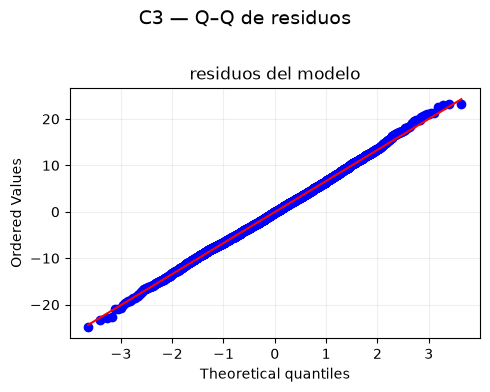

Shapiro–Wilk rechaza normalidad formal al nivel α = 0,05.
Interpretación conjunta: W se mantiene cercano a 1 y el Q–Q sigue la recta en términos generales, con desviaciones pequeñas en las colas; con una muestra grande, Shapiro puede detectar desviaciones pequeñas.
Decisión conservadora conforme a la guía: se usan contrastes por permutación para C3 e intervalos bootstrap para los coeficientes; esto no demuestra que todos los demás supuestos se cumplan.
Independencia: no certificable; el CSV no documenta muestreo, temporalidad ni identificadores únicos.
Limitación de la permutación: su interpretación depende de la intercambiabilidad bajo H₀, que no puede confirmarse con el archivo recibido.


,predictor,beta (puntos por unidad),t observado,p por permutación,IC bootstrap 95 % beta,beta estandarizado
0,gaming_hours,-5.230178,-160.139884,0.0005,[-5.296; -5.160],-0.539909
1,study_hours,6.279065,214.214848,0.0005,[6.221; 6.336],0.722221
2,sleep_hours,3.745636,71.460525,0.0005,[3.644; 3.844],0.241017
3,uso_no_gaming,0.026269,0.503990,0.5990,[-0.081; 0.119],0.001699
4,attendance,0.276029,42.595431,0.0005,[0.263; 0.289],0.143647


Regresión lineal múltiple: F global observado=16006.3938; p por permutación=< 0,001; R²=0.9092
Inferencia C3: 1,999 permutaciones por contraste; IC percentil bootstrap con 1,000 remuestreos de observaciones.


In [6]:
predictors = ["gaming_hours", "study_hours", "sleep_hours", "uso_no_gaming", "attendance"]
model_df = df[["grades"] + predictors].dropna().copy()
formula = "grades ~ gaming_hours + study_hours + sleep_hours + uso_no_gaming + attendance"
fit = smf.ols(formula, data=model_df).fit()

resid = np.asarray(fit.resid)
res_diag = shapiro_diag(resid, "residuos regresión", seed=SEED+100)
print("Diagnóstico de supuestos de regresión: Shapiro–Wilk y Q–Q de residuos.")
display(pd.DataFrame([{
    "diagnóstico": "Shapiro–Wilk residuos (máx. 5000)",
    "n evaluado": min(len(resid), 5000),
    "estadístico W": res_diag["W"],
    "p": res_diag["p_Shapiro"],
    "lectura": "se interpreta junto con el gráfico Q–Q y α = 0,05"
}]))
plot_qq_grid({"residuos del modelo": resid}, "C3 — Q–Q de residuos", ncols=1)
if res_diag["p_Shapiro"] < ALPHA:
    print("Shapiro–Wilk rechaza normalidad formal al nivel α = 0,05.")
    print("Interpretación conjunta: W se mantiene cercano a 1 y el Q–Q sigue la recta en términos generales, con desviaciones pequeñas en las colas; con una muestra grande, Shapiro puede detectar desviaciones pequeñas.")
    print("Decisión conservadora conforme a la guía: se usan contrastes por permutación para C3 e intervalos bootstrap para los coeficientes; esto no demuestra que todos los demás supuestos se cumplan.")
else:
    print("Shapiro–Wilk no rechaza normalidad formal al nivel α = 0,05; el gráfico Q–Q también se revisa antes de interpretar la regresión.")
print("Independencia: no certificable; el CSV no documenta muestreo, temporalidad ni identificadores únicos.")
print("Limitación de la permutación: su interpretación depende de la intercambiabilidad bajo H₀, que no puede confirmarse con el archivo recibido.")


def permutation_global_f(X, y, n_perm=N_PERM_REGRESSION, seed=SEED):
    """Prueba F global mediante permutación bajo H0 de ausencia de pendientes."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n, p = X.shape
    rank_x = int(np.linalg.matrix_rank(X))
    if rank_x < 2:
        raise ValueError("La matriz del modelo no contiene predictores independientes del intercepto.")
    q_full = np.linalg.qr(X, mode="reduced")[0]
    y_mean = float(y.mean())
    e0 = y - y_mean
    rss_reduced = float(np.dot(e0, e0))
    projection = q_full.T @ y
    rss_full = max(0.0, float(np.dot(y, y) - np.dot(projection, projection)))
    df_num = rank_x - 1
    df_den = n - rank_x
    f_observed = ((rss_reduced - rss_full) / df_num) / (rss_full / df_den)

    local_rng = np.random.default_rng(seed)
    exceed = 0
    for _ in range(n_perm):
        y_star = y_mean + local_rng.permutation(e0)
        proj_star = q_full.T @ y_star
        rss_star = max(1e-12, float(np.dot(y_star, y_star) - np.dot(proj_star, proj_star)))
        f_star = ((rss_reduced - rss_star) / df_num) / (rss_star / df_den)
        exceed += (f_star >= f_observed)
    p_perm = (exceed + 1) / (n_perm + 1)
    return {"F": float(f_observed), "df_num": df_num, "df_den": df_den, "p_perm": float(p_perm)}


def freedman_lane_coefficient_test(X, y, predictor_index, t_observed,
                                   n_perm=N_PERM_REGRESSION, seed=SEED):
    """Prueba bilateral por permutación de Freedman–Lane para un coeficiente."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n, p = X.shape
    nuisance_columns = [j for j in range(p) if j != predictor_index]
    X_reduced = X[:, nuisance_columns]
    q_reduced = np.linalg.qr(X_reduced, mode="reduced")[0]
    fitted_reduced = q_reduced @ (q_reduced.T @ y)
    residual_reduced = y - fitted_reduced

    x_interest = X[:, predictor_index]
    x_residualized = x_interest - q_reduced @ (q_reduced.T @ x_interest)
    ss_x = float(np.dot(x_residualized, x_residualized))
    if ss_x <= 0:
        raise ValueError("El predictor no añade variación independiente al modelo reducido.")

    rss_reduced = float(np.dot(residual_reduced, residual_reduced))
    df_den = n - int(np.linalg.matrix_rank(X))
    local_rng = np.random.default_rng(seed)
    exceed = 0
    for _ in range(n_perm):
        residual_permuted = local_rng.permutation(residual_reduced)
        beta_star = float(np.dot(x_residualized, residual_permuted) / ss_x)
        rss_full_star = max(1e-12, rss_reduced - beta_star**2 * ss_x)
        se_star = np.sqrt((rss_full_star / df_den) / ss_x)
        t_star = beta_star / se_star if se_star > 0 else np.inf
        exceed += (abs(t_star) >= abs(t_observed))
    p_perm = (exceed + 1) / (n_perm + 1)
    return float(p_perm)


def bootstrap_ols_coefficient_ci(X, y, n_boot=N_BOOT_REGRESSION, seed=SEED):
    """IC percentil bootstrap de coeficientes por remuestreo de filas completas."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n, p = X.shape
    local_rng = np.random.default_rng(seed)
    boot_coefs = np.empty((n_boot, p), dtype=float)
    for b in range(n_boot):
        ids = local_rng.integers(0, n, size=n)
        boot_coefs[b, :] = np.linalg.lstsq(X[ids, :], y[ids], rcond=None)[0]
    limits = np.nanpercentile(boot_coefs, [100*ALPHA/2, 100*(1-ALPHA/2)], axis=0)
    return {j: (float(limits[0, j]), float(limits[1, j])) for j in range(p)}


def bootstrap_r2_ci(X, y, n_boot=1000, seed=SEED):
    """IC percentil bootstrap del R² por remuestreo de filas completas."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(y)
    local_rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        ids = local_rng.integers(0, n, size=n)
        xb, yb = X[ids], y[ids]
        beta = np.linalg.lstsq(xb, yb, rcond=None)[0]
        errors = yb - xb @ beta
        denominator = np.sum((yb - yb.mean())**2)
        values.append(1 - np.sum(errors**2)/denominator if denominator > 0 else np.nan)
    return tuple(np.nanpercentile(values, [100*ALPHA/2, 100*(1-ALPHA/2)]))


X_main = np.asarray(fit.model.exog, dtype=float)
y_main = model_df["grades"].to_numpy(dtype=float)
exog_names = list(fit.model.exog_names)
rank_main = int(np.linalg.matrix_rank(X_main))
df_num = rank_main - 1
df_den = len(y_main) - rank_main
r2_ci = bootstrap_r2_ci(X_main, y_main, n_boot=1000, seed=SEED+101)
coef_ci_by_index = bootstrap_ols_coefficient_ci(X_main, y_main, n_boot=N_BOOT_REGRESSION, seed=SEED+102)
perm_global = permutation_global_f(X_main, y_main, n_perm=N_PERM_REGRESSION, seed=SEED+110)
f2_global = fit.rsquared/(1-fit.rsquared) if fit.rsquared < 1 else np.inf

assump_reg = (
    f"Shapiro residuos W={res_diag['W']:.6f}, p={res_diag['p_Shapiro']:.3g}; Q–Q con alineación general y desviaciones leves en colas; "
    f"inferencias por permutación; IC de coeficientes por bootstrap (n={N_BOOT_REGRESSION}); "
    "Levene no aplica a esta regresión; independencia no verificable por falta de información de muestreo"
)

add_primary("C3-F", "Global; H₀: todas las pendientes β = 0; H₁: al menos una pendiente β ≠ 0", "significancia conjunta de los cinco predictores", "Regresión múltiple", "F global por permutación",
            f"F={perm_global['F']:.4f}", f"{perm_global['df_num']}, {perm_global['df_den']}", perm_global["p_perm"],
            f"IC bootstrap 95 % R² {fmt_ci(r2_ci)}", f"R²={fit.rsquared:.4f}; f²={f2_global:.4f}",
            assump_reg, "asociación conjunta de los predictores",
            "El contraste global por permutación evalúa asociación conjunta; no implica causalidad.")

coef_rows = []
coef_tables = []
for v in predictors:
    beta = float(fit.params[v])
    tval = float(fit.tvalues[v])
    coef_index = exog_names.index(v)
    ci_boot = coef_ci_by_index[coef_index]
    p_perm = freedman_lane_coefficient_test(
        X_main, y_main, coef_index, tval,
        n_perm=N_PERM_REGRESSION,
        seed=SEED + 200 + coef_index
    )
    beta_std = beta * (model_df[v].std(ddof=1) / model_df["grades"].std(ddof=1))
    coef_rows.append({
        "predictor": v,
        "beta (puntos por unidad)": beta,
        "t observado": tval,
        "p por permutación": p_perm,
        "IC bootstrap 95 % beta": fmt_ci(ci_boot),
        "beta estandarizado": beta_std
    })
    expected = ("negativa" if v == "gaming_hours" else "positiva" if v in ["study_hours", "sleep_hours", "attendance"] else "sin dirección fijada")
    hypothesis_label = {"gaming_hours":"H1", "study_hours":"H2", "sleep_hours":"H4a", "attendance":"H4b"}.get(v, "Ajuste")
    hypothesis = f"{hypothesis_label}; H₀: β({v}) = 0; H₁: β({v}) ≠ 0"
    add_primary(
        f"C3-{v}", hypothesis, f"coeficiente {v}=0", "Regresión múltiple",
        "t del coeficiente con p por permutación (Freedman–Lane)",
        f"t={tval:.4f}", str(df_den), p_perm,
        f"IC bootstrap 95 % β {fmt_ci(ci_boot)}",
        f"β={beta:.4f}; β estandarizado={beta_std:.4f}",
        assump_reg, f"dirección esperada {expected}",
        f"El coeficiente ajustado de {v} es {beta:.4f}; el valor p se obtuvo por permutación y la asociación no demuestra causalidad."
    )

coef_df = pd.DataFrame(coef_rows)
display(coef_df)
print(f"Regresión lineal múltiple: F global observado={perm_global['F']:.4f}; "
      f"p por permutación={format_p_report(perm_global['p_perm'])}; R²={fit.rsquared:.4f}")
print(f"Inferencia C3: {N_PERM_REGRESSION:,} permutaciones por contraste; IC percentil bootstrap con {N_BOOT_REGRESSION:,} remuestreos de observaciones.")

## 7. C4 — Factorial `gaming_cat × study_cat`

Se presentan tres contrastes: efecto de `gaming_cat`, efecto de `study_cat` e interacción entre ambos factores. La interacción corresponde a H3.

Antes del análisis se revisan Shapiro–Wilk de los residuos, Q–Q y Levene entre las nueve celdas. Si fallan los supuestos paramétricos, los valores p se estiman con modelos por permutación (Freedman–Lane). Se informan F observado, grados de libertad, valor p, η² parcial e IC 95 % del tamaño del efecto.

Tamaños de las nueve celdas:


,celda,n
0,gaming=Bajo; estudio=Bajo,867
1,gaming=Bajo; estudio=Medio,896
2,gaming=Bajo; estudio=Alto,908
3,gaming=Medio; estudio=Bajo,898
4,gaming=Medio; estudio=Medio,879
5,gaming=Medio; estudio=Alto,890
6,gaming=Alto; estudio=Bajo,903
7,gaming=Alto; estudio=Medio,894
8,gaming=Alto; estudio=Alto,865


Normalidad por celda:


,variable,n,W,p_Shapiro,asimetría,nota
0,gaming=Bajo; estudio=Bajo,867,0.997093,1.204405e-01,-0.160203,muestra completa
1,gaming=Bajo; estudio=Medio,896,0.983465,1.570582e-08,-0.124547,muestra completa
2,gaming=Bajo; estudio=Alto,908,0.768845,7.397576e-34,-1.381822,muestra completa
3,gaming=Medio; estudio=Bajo,898,0.997482,1.843662e-01,-0.089836,muestra completa
4,gaming=Medio; estudio=Medio,879,0.997901,3.438687e-01,-0.028794,muestra completa
5,gaming=Medio; estudio=Alto,890,0.961733,1.664786e-14,-0.446872,muestra completa
6,gaming=Alto; estudio=Bajo,903,0.997083,1.013437e-01,0.036007,muestra completa
7,gaming=Alto; estudio=Medio,894,0.996940,8.547319e-02,-0.069072,muestra completa
8,gaming=Alto; estudio=Alto,865,0.990052,1.360158e-05,-0.286649,muestra completa


Levene entre las nueve celdas: W=50.4199, p=4.26e-80


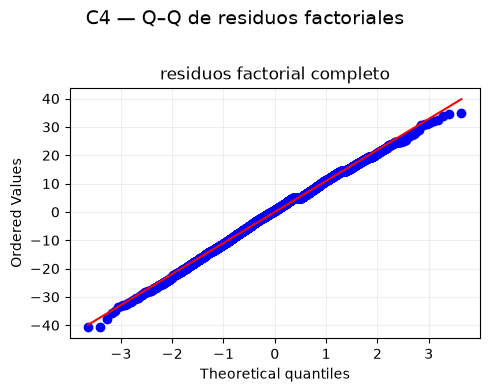

Método principal: permutación Freedman–Lane (supuestos paramétricos no satisfechos)


,ID,término,F observado,gl1,gl2,p permutación,η² parcial,IC bootstrap η² parcial
0,C4-G,gaming_cat (ajustado por estudio),4245.034330,2,7995,0.001,0.515016,[0.503; 0.527]
1,C4-S,study_cat (ajustado por gaming),7676.537235,2,7995,0.001,0.657573,[0.648; 0.667]
2,C4-INT,interacción gaming_cat × study_cat,94.176358,4,7991,0.001,0.045019,[0.036; 0.054]


Medias por combinación gaming × estudio (puntos sobre 100):


study_cat,Bajo,Medio,Alto
gaming_cat,,,
Bajo,63.029908,80.762623,95.221178
Medio,48.912795,66.178294,85.673607
Alto,31.320908,48.485034,75.375827


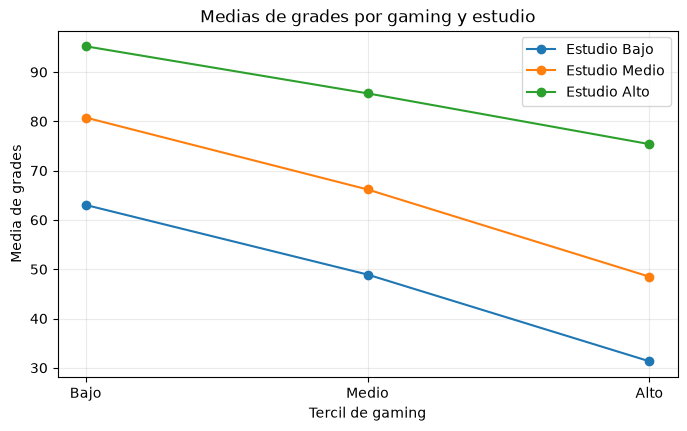

In [7]:
# Nueve celdas y supuestos.
cell_values=[]; cell_labels=[]
for g in gaming_levels:
    for s in gaming_levels:
        vals=df.loc[(df["gaming_cat"]==g)&(df["study_cat"]==s),"grades"].dropna().to_numpy()
        cell_values.append(vals); cell_labels.append(f"gaming={g}; estudio={s}")
cell_sizes=pd.DataFrame({"celda":cell_labels,"n":[len(v) for v in cell_values]})
print("Tamaños de las nueve celdas:")
display(cell_sizes)
normality_c4=pd.DataFrame([shapiro_diag(v,label,seed=SEED+200+i) for i,(v,label) in enumerate(zip(cell_values,cell_labels))])
levene_c4=stats.levene(*cell_values,center="median")
print("Normalidad por celda:"); display(normality_c4)
print(f"Levene entre las nueve celdas: W={levene_c4.statistic:.4f}, p={levene_c4.pvalue:.4g}")

# Q–Q del modelo factorial completo.
df_factorial=df.dropna(subset=["grades","gaming_cat","study_cat"]).copy()
fit_factorial_diag=smf.ols("grades ~ C(gaming_cat) * C(study_cat)",data=df_factorial).fit()
res_factorial=np.asarray(fit_factorial_diag.resid)
plot_qq_grid({"residuos factorial completo":res_factorial},"C4 — Q–Q de residuos factoriales",ncols=1)
normality_res_c4=shapiro_diag(res_factorial,"residuos factorial",seed=SEED+220)
use_permutation=bool((normality_c4["p_Shapiro"]<ALPHA).any() or levene_c4.pvalue<ALPHA or normality_res_c4["p_Shapiro"]<ALPHA)
print("Método principal:","permutación Freedman–Lane (supuestos paramétricos no satisfechos)" if use_permutation else "ANOVA factorial paramétrico (diagnósticos sin alerta clara)")

# Matrices anidadas para efectos principales en modelo aditivo e interacción.
df_fac_sorted=df_factorial.sort_values(["gaming_cat","study_cat"]).reset_index(drop=True)
y_fac=df_fac_sorted["grades"].to_numpy(dtype=float)
X_g_red=np.asarray(dmatrix("1 + C(study_cat)",df_fac_sorted))
X_g_full=np.asarray(dmatrix("1 + C(study_cat) + C(gaming_cat)",df_fac_sorted))
X_s_red=np.asarray(dmatrix("1 + C(gaming_cat)",df_fac_sorted))
X_s_full=np.asarray(dmatrix("1 + C(gaming_cat) + C(study_cat)",df_fac_sorted))
X_i_red=np.asarray(dmatrix("1 + C(gaming_cat) + C(study_cat)",df_fac_sorted))
X_i_full=np.asarray(dmatrix("1 + C(gaming_cat) * C(study_cat)",df_fac_sorted))


def qr_basis(X):
    return np.linalg.qr(np.asarray(X,dtype=float),mode="reduced")[0]

def nested_f_from_q(y, Qr, Qf):
    y=np.asarray(y,dtype=float)
    rss_r=max(0.0,float(np.dot(y,y)-np.sum((Qr.T@y)**2)))
    rss_f=max(0.0,float(np.dot(y,y)-np.sum((Qf.T@y)**2)))
    df_num=Qf.shape[1]-Qr.shape[1]
    df_den=len(y)-Qf.shape[1]
    ss=max(0.0,rss_r-rss_f)
    f=((ss/df_num)/(rss_f/df_den)) if rss_f>0 and df_num>0 else 0.0
    eta=ss/(ss+rss_f) if ss+rss_f>0 else np.nan
    return f,df_num,df_den,eta,rss_r,rss_f

def freedman_lane_test(y,Xred,Xfull,n_perm=N_PERM_FACTORIAL,seed=SEED):
    local_rng=np.random.default_rng(seed)
    Qr,Qf=qr_basis(Xred),qr_basis(Xfull)
    fitted=Qr@(Qr.T@y)
    resid=y-fitted
    f_obs,dfn,dfd,eta_obs,_,_=nested_f_from_q(y,Qr,Qf)
    exceed=0
    for _ in range(n_perm):
        ystar=fitted+local_rng.permutation(resid)
        f_perm,_,_,_,_,_=nested_f_from_q(ystar,Qr,Qf)
        exceed += (f_perm >= f_obs)
    p_perm=(exceed+1)/(n_perm+1)
    return {"F":f_obs,"dfn":dfn,"dfd":dfd,"p_perm":p_perm,"eta_p2":eta_obs,"Qr":Qr,"Qf":Qf}

def bootstrap_factorial_eta_ci(df_sorted, row_col, col_col, y_col, Qr, Qf, n_boot=N_BOOT_FACTORIAL, seed=SEED):
    local_rng=np.random.default_rng(seed)
    cell_arrays=[]
    for g in gaming_levels:
        for s in gaming_levels:
            cell_arrays.append(df_sorted.loc[(df_sorted[row_col]==g)&(df_sorted[col_col]==s),y_col].to_numpy(dtype=float))
    values=[]
    for _ in range(n_boot):
        yb=np.concatenate([local_rng.choice(a,size=len(a),replace=True) for a in cell_arrays])
        _,_,_,eta,_,_=nested_f_from_q(yb,Qr,Qf)
        values.append(eta)
    return tuple(np.nanpercentile(values,[100*ALPHA/2,100*(1-ALPHA/2)]))

if use_permutation:
    c4_models=[
        ("C4-G", "gaming_cat (ajustado por estudio)", X_g_red, X_g_full, "H1"),
        ("C4-S", "study_cat (ajustado por gaming)", X_s_red, X_s_full, "H2"),
        ("C4-INT", "interacción gaming_cat × study_cat", X_i_red, X_i_full, "H3")
    ]
    c4_results=[]
    for i,(tid,label,xr,xf,hyp) in enumerate(c4_models):
        res=freedman_lane_test(y_fac,xr,xf,n_perm=N_PERM_FACTORIAL,seed=SEED+300+i)
        qr,qf=res["Qr"],res["Qf"]
        # Bootstrapping respects the original nine-cell design and uses the corresponding nested model spaces.
        ci_eta=bootstrap_factorial_eta_ci(df_fac_sorted,"gaming_cat","study_cat","grades",qr,qf,n_boot=N_BOOT_FACTORIAL,seed=SEED+330+i)
        c4_results.append({"ID":tid,"término":label,"F observado":res["F"],"gl1":res["dfn"],"gl2":res["dfd"],
                           "p permutación":res["p_perm"],"η² parcial":res["eta_p2"],"IC bootstrap η² parcial":fmt_ci(ci_eta)})
        add_primary(tid,hyp,label,"Factorial de dos factores","F parcial por permutación",
                    f"F={res['F']:.4f}",f"{res['dfn']}, {res['dfd']}",res["p_perm"],
                    f"IC bootstrap 95 % η² parcial {fmt_ci(ci_eta)}",f"η² parcial={res['eta_p2']:.4f}",
                    f"Shapiro residuos p={normality_res_c4['p_Shapiro']:.3g}; Shapiro por celda p min={normality_c4['p_Shapiro'].min():.3g}, max={normality_c4['p_Shapiro'].max():.3g}; Levene p={levene_c4.pvalue:.3g}; Q–Q; Freedman–Lane; independencia no verificable",
                    "efecto del factor / interacción",
                    f"Para {label}, η² parcial={res['eta_p2']:.3f}; el contraste por permutación {'muestra evidencia estadística' if res['p_perm']<ALPHA else 'no muestra evidencia suficiente'} al nivel nominal, antes del ajuste global BH.")
    c4_results_df=pd.DataFrame(c4_results)
else:
    # Si todos los diagnósticos fueran razonables, se reporta ANOVA factorial tipo II como alternativa paramétrica.
    import statsmodels.stats.anova as anova_module
    anova_table=anova_module.anova_lm(fit_factorial_diag,typ=2)
    c4_results=[]
    term_to_id={"C(gaming_cat)":"C4-G","C(study_cat)":"C4-S","C(gaming_cat):C(study_cat)":"C4-INT"}
    for term,tid in term_to_id.items():
        row=anova_table.loc[term]
        pval=float(row["PR(>F)"]); fval=float(row["F"]); dfn=int(row["df"]); dfd=int(fit_factorial_diag.df_resid)
        eta=float(row["sum_sq"]/(row["sum_sq"]+anova_table.loc["Residual","sum_sq"]))
        c4_results.append({"ID":tid,"término":term,"F observado":fval,"gl1":dfn,"gl2":dfd,"p permutación":pval,"η² parcial":eta,"IC bootstrap η² parcial":"No calculado por vía paramétrica"})
        add_primary(tid,"H3",term,"Factorial de dos factores","ANOVA factorial tipo II",f"F={fval:.4f}",f"{dfn}, {dfd}",pval,
                    "IC de η² parcial no disponible en esta vía",f"η² parcial={eta:.4f}",
                    f"Shapiro residuos p={normality_res_c4['p_Shapiro']:.3g}; Shapiro por celda p min={normality_c4['p_Shapiro'].min():.3g}, max={normality_c4['p_Shapiro'].max():.3g}; Levene p={levene_c4.pvalue:.3g}; Q–Q; independencia no verificable",
                    "efecto del factor / interacción","ANOVA factorial paramétrico; interpretar junto con el tamaño del efecto.")
    c4_results_df=pd.DataFrame(c4_results)

display(c4_results_df)

# Medias marginales descriptivas para facilitar la interpretación de los efectos.
print("Medias por combinación gaming × estudio (puntos sobre 100):")
mean_grid=df.pivot_table(index="gaming_cat",columns="study_cat",values="grades",aggfunc="mean",observed=False).reindex(index=gaming_levels,columns=gaming_levels)
display(mean_grid)
fig,ax=plt.subplots(figsize=(8,4.5))
for s in gaming_levels:
    ax.plot(gaming_levels,mean_grid[s].values,marker="o",label=f"Estudio {s}")
ax.set(title="Medias de grades por gaming y estudio",xlabel="Tercil de gaming",ylabel="Media de grades")
ax.legend(); ax.grid(alpha=.25); plt.show()

## 8. Bootstrap y comparación con IC clásico

Se estiman 10.000 remuestreos para el IC percentil bootstrap de la correlación de Pearson entre `gaming_hours` y `grades`, y se compara con el IC clásico por transformación de Fisher. Este apartado es una **estimación complementaria**, no una prueba de hipótesis adicional ni una fila más en el recuento de contrastes.

El bootstrap cuantifica incertidumbre bajo los datos disponibles; no corrige falta de representatividad, dependencia no observada ni el hecho de que el dataset sea simulado.

In [8]:
# B1: IC bootstrap de Pearson comparado con el IC clásico de Fisher.
x = df["gaming_hours"].to_numpy(dtype=float)
y = df["grades"].to_numpy(dtype=float)
r_b1 = float(np.corrcoef(x, y)[0, 1])
ci_fisher_b1 = fisher_ci(r_b1, len(df))
ci_boot_b1 = bootstrap_pearson_ci(x, y, n_boot=N_BOOT_CORE, seed=SEED+700)

bootstrap_table = pd.DataFrame([{
    "Estimación": "Pearson r(gaming_hours, grades)",
    "Estimador": r_b1,
    "IC 95 % bootstrap": fmt_ci(ci_boot_b1),
    "IC 95 % clásico (Fisher)": fmt_ci(ci_fisher_b1),
    "Comparación": "Los intervalos se comparan como estimaciones de incertidumbre; no se cuenta como prueba de hipótesis."
}])
display(bootstrap_table)
bootstrap_table.to_csv(OUTPUT_DIR/"fase2_intervalo_bootstrap.csv", index=False, encoding="utf-8-sig")

,Estimación,Estimador,IC 95 % bootstrap,IC 95 % clásico (Fisher),Comparación
0,"Pearson r(gaming_hours, grades)",-0.55823,[-0.573; -0.543],[-0.573; -0.543],Los intervalos se comparan como estimaciones d...


## 9. Corrección por comparaciones múltiples y tabla resumen

Cuando se realizan varias pruebas dentro de una misma familia, la corrección evita aumentar sin control la probabilidad de falsos positivos. Se utiliza **Benjamini–Hochberg** por familia estadística: correlaciones, regresión múltiple y los términos del factorial. Las tres comparaciones post hoc de C2 forman una familia separada y también se ajustan entre sí. La prueba global única de C2 no necesita una corrección dentro de su propia familia.

La tabla reúne todos los contrastes inferenciales ejecutados, incluidos los post hoc. El intervalo bootstrap de la sección anterior es una estimación y no se cuenta como contraste ni como valor p adicional.

In [9]:
# Tabla resumen única. BH se aplica por familia; los post hoc de C2 se ajustan entre sí.
summary_df = pd.DataFrame(primary_records)
if summary_df.empty:
    raise RuntimeError("No se registró ninguna prueba; revisar las secciones previas.")

summary_df["p ajustado BH"] = np.nan
for family, idx in summary_df.groupby("Familia").groups.items():
    summary_df.loc[idx, "p ajustado BH"] = multipletests(
        summary_df.loc[idx, "p"].to_numpy(), alpha=ALPHA, method="fdr_bh"
    )[1]

summary_df["Decisión"] = np.where(
    summary_df["p ajustado BH"] < ALPHA,
    "Rechazar H₀",
    "No hay evidencia suficiente para rechazar H₀"
)
summary_df["Conclusión en lenguaje natural"] = summary_df.apply(
    lambda r: r["Interpretación base"] + (
        " Se rechaza H₀ tras BH dentro de su familia." if r["p ajustado BH"] < ALPHA
        else " No hay evidencia suficiente para rechazar H₀ tras BH dentro de su familia."
    ), axis=1
)

posthoc_df = pd.DataFrame(posthoc_records)
if not posthoc_df.empty:
    posthoc_df["p ajustado BH"] = multipletests(
        posthoc_df["p"].to_numpy(), alpha=ALPHA, method="fdr_bh"
    )[1]
    posthoc_df["Hipótesis"] = "H1"
    posthoc_df["Familia"] = "Post hoc C2"
    posthoc_df["Prueba aplicada"] = posthoc_df["Prueba"]
    posthoc_df["Supuestos verificados"] = (
        "Hereda Shapiro–Wilk, Q–Q y Levene de C2; independencia no verificable"
    )
    posthoc_df["Estadístico (gl)"] = posthoc_df.apply(
        lambda r: f"z={r['Estadístico']:.4f} (n.a.)", axis=1
    )
    posthoc_df["Decisión"] = np.where(
        posthoc_df["p ajustado BH"] < ALPHA,
        "Rechazar H₀ del par",
        "No hay evidencia suficiente para rechazar H₀ del par"
    )
    posthoc_df["Conclusión en lenguaje natural"] = posthoc_df.apply(
        lambda r: r["Interpretación base"] + (
            " Hay evidencia de diferencia tras BH post hoc." if r["p ajustado BH"] < ALPHA
            else " No hay evidencia suficiente de diferencia tras BH post hoc."
        ), axis=1
    )

cols_show = [
    "ID", "Hipótesis", "Contraste", "Familia", "Prueba aplicada",
    "Supuestos verificados", "Estadístico (gl)", "p", "p ajustado BH",
    "IC 95 %", "Tamaño del efecto", "Decisión", "Conclusión en lenguaje natural"
]
summary_export = summary_df[cols_show].copy()
if not posthoc_df.empty:
    summary_export = pd.concat([summary_export, posthoc_df[cols_show]], ignore_index=True)
# Formulaciones explícitas para que cada fila del archivo reproducible sea interpretable por sí sola.
hypothesis_details = {
    "C1-1": ("H1 — Gaming y rendimiento", "H₀: ρₛ(gaming_hours, grades) = 0", "H₁: ρₛ(gaming_hours, grades) ≠ 0", "Las horas de gaming no presentan asociación monotónica con grades / sí presentan una asociación monotónica."),
    "C1-2": ("H2 — Estudio y rendimiento", "H₀: ρₛ(study_hours, grades) = 0", "H₁: ρₛ(study_hours, grades) ≠ 0", "Las horas de estudio no presentan asociación monotónica con grades / sí presentan una asociación monotónica."),
    "C1-3": ("H4a - Sueño", "H₀: ρₛ(sleep_hours, grades) = 0", "H₁: ρₛ(sleep_hours, grades) ≠ 0", "Las horas de sueño no presentan asociación monotónica con grades / sí presentan una asociación monotónica."),
    "C1-4": ("H4b - Asistencia", "H₀: ρₛ(attendance, grades) = 0", "H₁: ρₛ(attendance, grades) ≠ 0", "La asistencia no presenta asociación monotónica con grades / sí presenta una asociación monotónica."),
    "C2": ("H1 — Gaming y rendimiento", "H₀: la distribución de grades es igual en los tres terciles de gaming", "H₁: al menos una distribución de grades difiere", "Las calificaciones no difieren por tercil de gaming / al menos un tercil presenta una distribución distinta."),
    "C2-P1": ("H1 — Gaming y rendimiento (post hoc)", "H₀: los rangos de grades son iguales entre Bajo y Medio", "H₁: los rangos de grades difieren entre Bajo y Medio", "Las calificaciones no difieren entre los grupos Bajo y Medio / sí difieren."),
    "C2-P2": ("H1 — Gaming y rendimiento (post hoc)", "H₀: los rangos de grades son iguales entre Bajo y Alto", "H₁: los rangos de grades difieren entre Bajo y Alto", "Las calificaciones no difieren entre los grupos Bajo y Alto / sí difieren."),
    "C2-P3": ("H1 — Gaming y rendimiento (post hoc)", "H₀: los rangos de grades son iguales entre Medio y Alto", "H₁: los rangos de grades difieren entre Medio y Alto", "Las calificaciones no difieren entre los grupos Medio y Alto / sí difieren."),
    "C3-F": ("Modelo de regresión global", "H₀: todas las pendientes de gaming_hours, study_hours, sleep_hours, uso_no_gaming y attendance son cero", "H₁: al menos una de esas pendientes es distinta de cero", "Considerados en conjunto, los predictores no presentan asociación lineal con grades / al menos uno sí presenta asociación ajustada."),
    "C3-gaming_hours": ("H1 — Gaming y rendimiento", "H₀: β(gaming_hours) = 0", "H₁: β(gaming_hours) ≠ 0", "Gaming no presenta asociación lineal independiente con grades al ajustar los demás predictores / sí presenta asociación."),
    "C3-study_hours": ("H2 — Estudio y rendimiento", "H₀: β(study_hours) = 0", "H₁: β(study_hours) ≠ 0", "Estudio no presenta asociación lineal independiente con grades al ajustar los demás predictores / sí presenta asociación."),
    "C3-sleep_hours": ("H4a - Sueño", "H₀: β(sleep_hours) = 0", "H₁: β(sleep_hours) ≠ 0", "Sueño no presenta asociación lineal independiente con grades al ajustar los demás predictores / sí presenta asociación."),
    "C3-attendance": ("H4b - Asistencia", "H₀: β(attendance) = 0", "H₁: β(attendance) ≠ 0", "Asistencia no presenta asociación lineal independiente con grades al ajustar los demás predictores / sí presenta asociación."),
    "C3-uso_no_gaming": ("Predictor complementario del modelo", "H₀: β(uso_no_gaming) = 0", "H₁: β(uso_no_gaming) ≠ 0", "Uso no relacionado con gaming no presenta asociación lineal independiente con grades / sí presenta asociación."),
    "C4-G": ("Efecto principal de gaming (complementario a H1)", "H₀: todos los coeficientes principales de gaming_cat son cero al ajustar por study_cat", "H₁: al menos uno de esos coeficientes es distinto de cero", "Tras ajustar por estudio, no hay diferencias de calificación entre niveles de gaming / existe al menos una diferencia."),
    "C4-S": ("Efecto principal de estudio (complementario a H2)", "H₀: todos los coeficientes principales de study_cat son cero al ajustar por gaming_cat", "H₁: al menos uno de esos coeficientes es distinto de cero", "Tras ajustar por gaming, no hay diferencias de calificación entre niveles de estudio / existe al menos una diferencia."),
    "C4-INT": ("H3 — Interacción gaming × estudio", "H₀: todos los coeficientes de interacción gaming_cat × study_cat son cero", "H₁: al menos un coeficiente de interacción es distinto de cero", "La diferencia asociada con gaming no cambia según el nivel de estudio / cambia según el nivel de estudio."),
}

for test_id, details in hypothesis_details.items():
    mask = summary_export["ID"].eq(test_id)
    if mask.any():
        summary_export.loc[mask, "Hipótesis"] = details[0]
        summary_export.loc[mask, "H₀ formal"] = details[1]
        summary_export.loc[mask, "H₁ formal"] = details[2]
        summary_export.loc[mask, "Hipótesis en lenguaje natural"] = details[3]

# Para informar p que SciPy puede representar como 0 por subdesbordamiento numérico, se agrega una columna de presentación.
# La columna p original se conserva numérica para que siga siendo utilizable en cálculos y auditoría.
summary_export["p para reporte"] = summary_export["p"].map(format_p_report)
summary_export["p ajustado BH para reporte"] = summary_export["p ajustado BH"].map(format_p_report)
summary_export = summary_export.sort_values(["Familia", "ID"]).reset_index(drop=True)

# Versión legible en pantalla; se conserva la p numérica para cálculos y su versión reportable como texto.
summary_display = summary_export.copy()
summary_display["p"] = summary_display["p"].map(format_p_report)
summary_display["p ajustado BH"] = summary_display["p ajustado BH"].map(format_p_report)
# La tabla final muestra H₀/H₁ y una formulación natural por cada contraste.
final_display_cols = [
    "ID", "Hipótesis", "H₀ formal", "H₁ formal", "Hipótesis en lenguaje natural",
    "Contraste", "Familia", "Prueba aplicada", "Supuestos verificados",
    "Estadístico (gl)", "p para reporte", "p ajustado BH para reporte",
    "IC 95 %", "Tamaño del efecto", "Decisión", "Conclusión en lenguaje natural"
]
summary_display = summary_export[final_display_cols].copy()
display(summary_display)

n_main = len(summary_df)
n_posthoc = len(posthoc_df)
print(f"Contrastes principales: {n_main}; comparaciones post hoc: {n_posthoc}; total en la tabla: {len(summary_export)}")
print("Ajuste BH: dentro de cada familia estadística; post hoc C2 se ajusta por separado.")
summary_export.to_csv(OUTPUT_DIR/"fase2_tabla_resumen_contrastes.csv", index=False, encoding="utf-8-sig")
print("Tabla exportada en formato reproducible: p numérico para auditoría y columnas de presentación (p < 0,001 cuando corresponde):", (OUTPUT_DIR/"fase2_tabla_resumen_contrastes.csv").relative_to(project_root))

# Resumen de evidencia para orientar la conclusión sin convertir asociaciones en causalidad.
def result_row(test_id):
    found = summary_export.loc[summary_export["ID"] == test_id]
    return None if found.empty else found.iloc[0]

def decision_text(row):
    if row is None:
        return "sin resultado registrado"
    return "evidencia estadística tras BH" if row["p ajustado BH"] < ALPHA else "sin evidencia suficiente tras BH"

print("\nLectura sintética de las hipótesis (α = 0,05, valores p ajustados dentro de la familia):")
for title, ids in [
    ("H1 — Gaming y rendimiento", ["C1-1", "C3-gaming_hours"]),
    ("H2 — Estudio y rendimiento", ["C1-2", "C3-study_hours"]),
    ("H3 — Interacción gaming × estudio", ["C4-INT"]),
    ("H4a - Sueño", ["C1-3", "C3-sleep_hours"]),
    ("H4b - Asistencia", ["C1-4", "C3-attendance"]),
]:
    pieces=[]
    for test_id in ids:
        row=result_row(test_id)
        if row is not None:
            pieces.append(f"{test_id}: {decision_text(row)}")
    print(f"- {title}: " + "; ".join(pieces) + ".")

sig_predictors=[]
for v in ["gaming_hours", "study_hours", "sleep_hours", "uso_no_gaming", "attendance"]:
    row=result_row(f"C3-{v}")
    if row is not None and row["p ajustado BH"] < ALPHA:
        sig_predictors.append(v)
print("\nVariables con coeficiente individual asociado a grades tras BH en este modelo:", ", ".join(sig_predictors) if sig_predictors else "ninguna")
print("Esta lista orienta la selección para Fase 3; la evidencia inferencial no sustituye la evaluación predictiva ni implica causalidad.")

,ID,Hipótesis,H₀ formal,H₁ formal,Hipótesis en lenguaje natural,Contraste,Familia,Prueba aplicada,Supuestos verificados,Estadístico (gl),p para reporte,p ajustado BH para reporte,IC 95 %,Tamaño del efecto,Decisión,Conclusión en lenguaje natural
0,C2,H1 — Gaming y rendimiento,H₀: la distribución de grades es igual en los ...,H₁: al menos una distribución de grades difiere,Las calificaciones no difieren por tercil de g...,grades entre gaming_cat Bajo/Medio/Alto,Comparar tres o más grupos,Kruskal–Wallis,"Shapiro p por grupo=[0.0, 0.0, 0.0]; Q–Q gener...",H=2110.1479 (2),"< 0,001","< 0,001",IC bootstrap 95 % del tamaño del efecto [0.247...,epsilon²=0.2636; IC bootstrap 95 % [0.247; 0.281],Rechazar H₀,El contraste global muestra diferencias entre ...
1,C1-1,H1 — Gaming y rendimiento,"H₀: ρₛ(gaming_hours, grades) = 0","H₁: ρₛ(gaming_hours, grades) ≠ 0",Las horas de gaming no presentan asociación mo...,gaming_hours ↔ grades,Correlación,Spearman,Shapiro x p=1.15e-36; grades p=2.67e-30; Q–Q g...,rho=-0.5473 (n.a.),"< 0,001","< 0,001",[-0.563; -0.531],Spearman=-0.547 (grande); Pearson r descriptiv...,Rechazar H₀,La asociación observada entre gaming_hours y g...
2,C1-2,H2 — Estudio y rendimiento,"H₀: ρₛ(study_hours, grades) = 0","H₁: ρₛ(study_hours, grades) ≠ 0",Las horas de estudio no presentan asociación m...,study_hours ↔ grades,Correlación,Spearman,Shapiro x p=2.6e-36; grades p=2.67e-30; Q–Q ge...,rho=0.7420 (n.a.),"< 0,001","< 0,001",[0.732; 0.751],Spearman=0.742 (grande); Pearson r descriptivo...,Rechazar H₀,La asociación observada entre study_hours y gr...
3,C1-3,H4a - Sueño,"H₀: ρₛ(sleep_hours, grades) = 0","H₁: ρₛ(sleep_hours, grades) ≠ 0",Las horas de sueño no presentan asociación mon...,sleep_hours ↔ grades,Correlación,Spearman,Shapiro x p=4.92e-36; grades p=2.67e-30; Q–Q g...,rho=0.2385 (n.a.),"< 0,001","< 0,001",[0.218; 0.260],Spearman=0.239 (pequeño); Pearson r descriptiv...,Rechazar H₀,La asociación observada entre sleep_hours y gr...
4,C1-4,H4b - Asistencia,"H₀: ρₛ(attendance, grades) = 0","H₁: ρₛ(attendance, grades) ≠ 0",La asistencia no presenta asociación monotónic...,attendance ↔ grades,Correlación,Spearman,Shapiro x p=2.74e-37; grades p=2.67e-30; Q–Q g...,rho=0.1257 (n.a.),"< 0,001","< 0,001",[0.104; 0.148],Spearman=0.126 (pequeño); Pearson r descriptiv...,Rechazar H₀,La asociación observada entre attendance y gra...
5,C4-G,Efecto principal de gaming (complementario a H1),H₀: todos los coeficientes principales de gami...,H₁: al menos uno de esos coeficientes es disti...,"Tras ajustar por estudio, no hay diferencias d...",gaming_cat (ajustado por estudio),Factorial de dos factores,F parcial por permutación,Shapiro residuos p=3.43e-08; Shapiro por celda...,"F=4245.0343 (2, 7995)",0.001,0.001,IC bootstrap 95 % η² parcial [0.503; 0.527],η² parcial=0.5150,Rechazar H₀,"Para gaming_cat (ajustado por estudio), η² par..."
6,C4-INT,H3 — Interacción gaming × estudio,H₀: todos los coeficientes de interacción gami...,H₁: al menos un coeficiente de interacción es ...,La diferencia asociada con gaming no cambia se...,interacción gaming_cat × study_cat,Factorial de dos factores,F parcial por permutación,Shapiro residuos p=3.43e-08; Shapiro por celda...,"F=94.1764 (4, 7991)",0.001,0.001,IC bootstrap 95 % η² parcial [0.036; 0.054],η² parcial=0.0450,Rechazar H₀,"Para interacción gaming_cat × study_cat, η² pa..."
7,C4-S,Efecto principal de estudio (complementario a H2),H₀: todos los coeficientes principales de stud...,H₁: al menos uno de esos coeficientes es disti...,"Tras ajustar por gaming, no hay diferencias de...",study_cat (ajustado por gaming),Factorial de dos factores,F parcial por permutación,Shapiro residuos p=3.43e-08; Shapiro por celda...,"F=7676.5372 (2, 7995)",0.001,0.001,IC bootstrap 95 % η² parcial [0.648; 0.667],η² parcial=0.6576,Rechazar H₀,"Para study_cat (ajustado por gaming), η² parci..."
8,C2-P1,H1 — Gaming y rendimiento (post hoc),H₀: los rangos de grades son iguales entre Baj...,H₁: los rangos de grades difieren e

Contrastes principales: 14; comparaciones post hoc: 3; total en la tabla: 17
Ajuste BH: dentro de cada familia estadística; post hoc C2 se ajusta por separado.
Tabla exportada en formato reproducible: p numérico para auditoría y columnas de presentación (p < 0,001 cuando corresponde): output\fase2_tabla_resumen_contrastes.csv

Lectura sintética de las hipótesis (α = 0,05, valores p ajustados dentro de la familia):
- H1 — Gaming y rendimiento: C1-1: evidencia estadística tras BH; C3-gaming_hours: evidencia estadística tras BH.
- H2 — Estudio y rendimiento: C1-2: evidencia estadística tras BH; C3-study_hours: evidencia estadística tras BH.
- H3 — Interacción gaming × estudio: C4-INT: evidencia estadística tras BH.
- H4a - Sueño: C1-3: evidencia estadística tras BH; C3-sleep_hours: evidencia estadística tras BH.
- H4b - Asistencia: C1-4: evidencia estadística tras BH; C3-attendance: evidencia estadística tras BH.

Variables con coeficiente individual asociado a grades tras BH en este mode

## 10. Conclusiones de la Fase 2 y limitaciones

Las decisiones se leen con α = 0,05 y con los valores p ajustados por Benjamini–Hochberg dentro de cada familia. **Rechazar H₀ significa que hay evidencia estadística de asociación/diferencia en estos datos; no demuestra causalidad ni garantiza que el resultado sea generalizable.** Si no se rechaza H₀, se informa que no hay evidencia suficiente para rechazarla; no se afirma que H₀ haya sido aceptada.

### Qué indican los resultados y su relevancia práctica

- **H1 — Gaming y rendimiento:** la correlación de Spearman es negativa (ρₛ = −0,547; IC 95 % [−0,563; −0,531]) y el coeficiente ajustado de `gaming_hours` es β = −5,230 puntos de `grades` por hora (IC bootstrap 95 % [−5,296; −5,160]). Ambos contrastes muestran evidencia tras BH. En la comparación por terciles, las diferencias de medianas de calificación son de aproximadamente 14,66 puntos entre Bajo y Medio, 17,33 entre Medio y Alto y 31,99 entre Bajo y Alto. En la escala de calificación de 0 a 100, las magnitudes son relevantes dentro de este archivo, pero no prueban que jugar cause un descenso de notas.
- **H2 — Estudio y rendimiento:** la correlación de Spearman es positiva (ρₛ = 0,742; IC 95 % [0,732; 0,751]) y el coeficiente ajustado es β = 6,279 puntos por hora de estudio (IC bootstrap 95 % [6,221; 6,336]). El efecto principal de `study_cat` en el factorial también presenta η² parcial = 0,658. La asociación es grande dentro del modelo y del dataset recibido, pero no debe extrapolarse automáticamente a estudiantes reales.
- **H3 — Interacción gaming × estudio:** el contraste de interacción presenta η² parcial = 0,045 (IC bootstrap 95 % [0,036; 0,054]) y p ajustado = 0,001. El valor p llega a la resolución mínima de este contraste (999 permutaciones; p mínimo posible = 0,001), así que no debe interpretarse como un valor exacto más preciso. La interacción tiene menor magnitud que los efectos principales de gaming y estudio en este modelo, aunque indica que las diferencias asociadas con gaming varían según el nivel de estudio.
- **H4a - Sueño:** la correlación de Spearman es positiva pequeña (rho_s = 0,239; IC 95 % [0,218; 0,260]) y el coeficiente ajustado es beta = 3,746 para `sleep_hours` (IC bootstrap 95 % [3,644; 3,844]). Ambos contrastes muestran evidencia estadística tras BH.
- **H4b - Asistencia:** la correlación de Spearman es positiva pequeña (rho_s = 0,126; IC 95 % [0,104; 0,148]) y el coeficiente ajustado es beta = 0,276 para `attendance` (IC bootstrap 95 % [0,263; 0,289]). Ambos contrastes muestran evidencia estadística tras BH. Las asociaciones por rango son más pequeñas que las de estudio y gaming; el significado práctico de una unidad de asistencia depende de la escala utilizada en el CSV.

Los tamaños del efecto y las diferencias en puntos muestran por qué el valor p no basta por sí solo: con 8.000 filas, incluso asociaciones pequeñas pueden ser estadísticamente significativas. Por eso se informa la magnitud y el intervalo de confianza, sin establecer umbrales de importancia que la guía no especifica.

### Posible variable de confusión

Una posible variable de confusión sería el **rendimiento académico previo**, porque puede relacionarse tanto con los hábitos de videojuegos como con la calificación observada. También podrían influir el contexto socioeconómico o la autorregulación del tiempo. El archivo no contiene mediciones suficientes para evaluar estos factores; por tanto, se plantean como posibles explicaciones no controladas, no como confusores demostrados.

### Limitaciones de la inferencia

- **Tamaño muestral:** hay 8.000 filas. Este tamaño aumenta la precisión dentro del archivo y puede hacer que efectos pequeños resulten estadísticamente significativos.
- **Representatividad:** no se documenta un método de muestreo ni una población objetivo, por lo que no se puede afirmar que la muestra represente a todos los estudiantes.
- **Independencia y dependencia temporal:** no se dispone de `student_id`, fechas ni diseño de muestreo; no se puede certificar la independencia ni descartar dependencia entre observaciones.
- **Datos simulados:** los resultados pueden reflejar reglas utilizadas para generar el dataset y no necesariamente relaciones del mundo real.
- **Tope de la respuesta:** `grades` contiene observaciones en 100, lo que puede afectar la distribución y las asociaciones estimadas.
- **Confusión y causalidad inversa:** el diseño transversal no permite establecer temporalidad ni descartar variables omitidas.

### Variables candidatas para la Fase 3

La evidencia inferencial respalda priorizar para evaluación predictiva `gaming_hours`, `study_hours`, `sleep_hours` y `attendance`. `gaming_cat`, `study_cat` y su interacción pueden evaluarse como variables derivadas por la señal observada en el análisis factorial. `uso_no_gaming` no muestra evidencia de asociación lineal independiente en la regresión tras el ajuste BH (p ajustado = 0,599), por lo que no se prioriza solo por la inferencia de esta fase; no es motivo suficiente, por sí solo, para descartarla de un modelo predictivo. La selección definitiva deberá depender de la evaluación predictiva de la Fase 3, no únicamente de la significancia estadística.
